# 06 · How observer orbit uncertainty affects Gateway tracking
Map the LSO-updated observer covariance into observer-to-Gateway angular and angular-rate uncertainty.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "configs" / "baseline.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "configs" / "baseline.json").exists():
    raise RuntimeError("Open this notebook from the project root or notebooks directory")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs" / "baseline.json")


## Main workflow
Initial observer P₀ → CR3BP covariance propagation → LSO angle/rate covariance updates → observer-to-Gateway measurement geometry. This does not require Monte Carlo. Gateway is treated as a known reference trajectory; the output is the observer-induced contribution, not Gateway orbit-estimation error.

The Gateway normalized state is sourced from `scripts/build_target_case_database.m` in the earlier cislunar project. Both spacecraft begin at their supplied phase at model t=0; this is not an epoch-specific mission simulation. That source uses TU=375695 s; this study retains its explicitly configured TU=375190.25852 s for all physical rates and timing. The normalized CR3BP states are used consistently with the study scaling; this is not a reproduction of the prior dimensional results.

In [2]:
from halo_tracking.horizons import forecast_horizons
from halo_tracking.tracking import gateway_tracking_history
forecast = forecast_horizons(cfg, periods=[1, 5, 10, 20])
tracking = gateway_tracking_history(forecast)

/workspace/scratch/678b6a3ef004/Halo_Orbit_Tracking/src/halo_tracking/horizons.py:25: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  result = make_truth(config, extra_times=checkpoints)


## Observer contribution to pointing uncertainty
For known Gateway position, the transverse observer position covariance maps to a two-axis tangent-plane pointing covariance. The full six-state covariance also maps to angular-rate uncertainty. Range and viewing direction matter, so equal observer position RSS σ need not imply equal pointing σ.

These curves are geometrical, not visibility-gated optical performance: lunar/Earth occultation, Sun exclusions and target brightness for the spacecraft camera are not yet modeled.

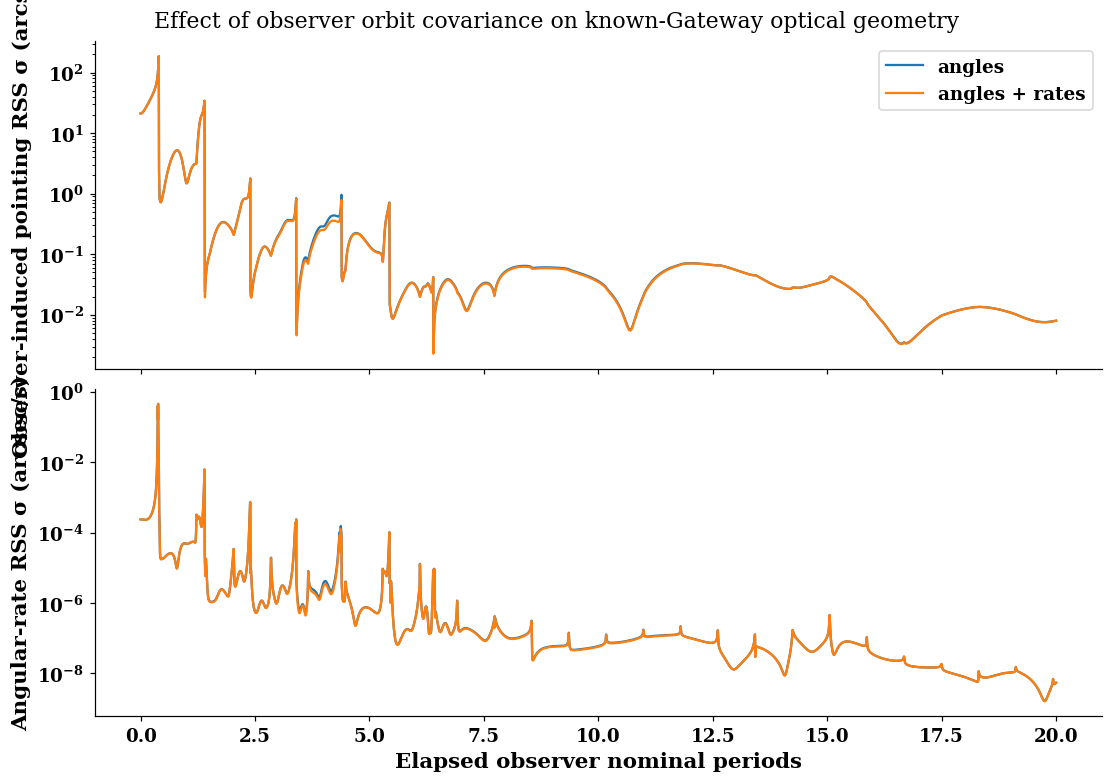

In [3]:
from halo_tracking.plotting import gateway_pointing_uncertainty, export
fig = gateway_pointing_uncertainty(tracking, cfg)
export(fig, ROOT / "results/tracking/gateway_pointing.png")

In [4]:
import numpy as np
from IPython.display import HTML, display
rows=[]
for period in [1, 5, 10, 20]:
    k=np.searchsorted(forecast["times"], period*cfg["orbit"]["period_tu"])
    for name in ["angles", "angles_rates"]:
        row=(period, name, tracking[name]["range_km"][k], tracking[name]["pointing_rss_sigma_arcsec"][k], tracking[name]["angular_rate_rss_sigma_arcsec_s"][k])
        rows.append("<tr>"+"".join("<td>"+(f"{x:.6g}" if isinstance(x,(float,int,np.floating)) else x)+"</td>" for x in row)+"</tr>")
display(HTML("<table><tr><th>Periods</th><th>LSO measurement case</th><th>Gateway range (km)</th><th>Pointing RSS σ (arcsec)</th><th>Angular-rate RSS σ (arcsec/s)</th></tr>"+"".join(rows)+"</table>"))

Periods,LSO measurement case,Gateway range (km),Pointing RSS σ (arcsec),Angular-rate RSS σ (arcsec/s)
1,angles,18432.5,1.50135,4.81038e-05
1,angles_rates,18432.5,1.49936,4.81007e-05
5,angles,16696.9,0.13701,7.08604e-07
5,angles_rates,16696.9,0.134262,6.96002e-07
10,angles,911346,0.0359763,5.94499e-08
10,angles_rates,911346,0.0348017,5.76055e-08
20,angles,874918,0.00801374,5.46648e-09
20,angles_rates,874918,0.00797714,5.44028e-09


## Interpretation limits
The supplied observer initial-value trajectory departs the halo region by roughly ten nominal periods. Both trajectories are propagated continuously without stationkeeping. Existing observer EKF covariance inconsistency carries into these predictions. Treat the values as conditional local forecasts, not validated pointing accuracy.

For independent camera noise, the observer contribution can enter a single-epoch measurement error budget. Across epochs it is correlated, so Gateway orbit estimation should use a joint/consider filter or an explicitly correlated model rather than repeatedly treating observer error as independent white noise.

In [5]:
output = ROOT / "results/tracking"
output.mkdir(parents=True, exist_ok=True)
arrays = {"times": tracking["times"], "gateway_state": tracking["gateway_state"]}
for name in ["angles", "angles_rates"]:
    for key,value in tracking[name].items():
        arrays[name+"_"+key]=value
np.savez_compressed(output / "gateway_pointing.npz", **arrays)